In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize']=(12,5)
sns.set_style('whitegrid')

In [3]:
df = pd.read_csv('train.csv',parse_dates=['date'])
df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [4]:
print("Shape:",df.shape)
print("\nData types:\n",df.dtypes)
print("\nMissing Values:\n",df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nDate range:", df['date'].min().date(), "to", df['date'].max().date())
print("Days covered:", df['date'].nunique())
print("Stores:", df['store'].nunique(), "| Items:", df['item'].nunique())

Shape: (913000, 4)

Data types:
 date     datetime64[us]
store             int64
item              int64
sales             int64
dtype: object

Missing Values:
 date     0
store    0
item     0
sales    0
dtype: int64

Duplicate rows: 0

Date range: 2013-01-01 to 2017-12-31
Days covered: 1826
Stores: 10 | Items: 50


In [5]:
# Every store-item pair should have one row for every day
rows_per_pair = df.groupby(['store', 'item']).size()
print("Store-item pairs:", len(rows_per_pair))
print("Rows per pair - min:", rows_per_pair.min(), "| max:", rows_per_pair.max())

Store-item pairs: 500
Rows per pair - min: 1826 | max: 1826


In [6]:
print(df['sales'].describe().round(1))
print("\nDays with zero sales:", (df['sales'] == 0).sum())
print("Negative sales:", (df['sales'] < 0).sum())

count    913000.0
mean         52.3
std          28.8
min           0.0
25%          30.0
50%          47.0
75%          70.0
max         231.0
Name: sales, dtype: float64

Days with zero sales: 1
Negative sales: 0


In [7]:
df['year']      = df['date'].dt.year
df['month']     = df['date'].dt.month
df['weekday']   = df['date'].dt.dayofweek      # 0 = Monday ... 6 = Sunday
df['day_name']  = df['date'].dt.day_name()
df.head()

,date,store,item,sales,year,month,weekday,day_name
0,2013-01-01,1,1,13,2013,1,1,Tuesday
1,2013-01-02,1,1,11,2013,1,2,Wednesday
2,2013-01-03,1,1,14,2013,1,3,Thursday
3,2013-01-04,1,1,13,2013,1,4,Friday
4,2013-01-05,1,1,10,2013,1,5,Saturday


      total_sales  growth_%
year                       
2013      7941243       NaN
2014      9135482      15.0
2015      9536887       4.4
2016     10357160       8.6
2017     10733740       3.6


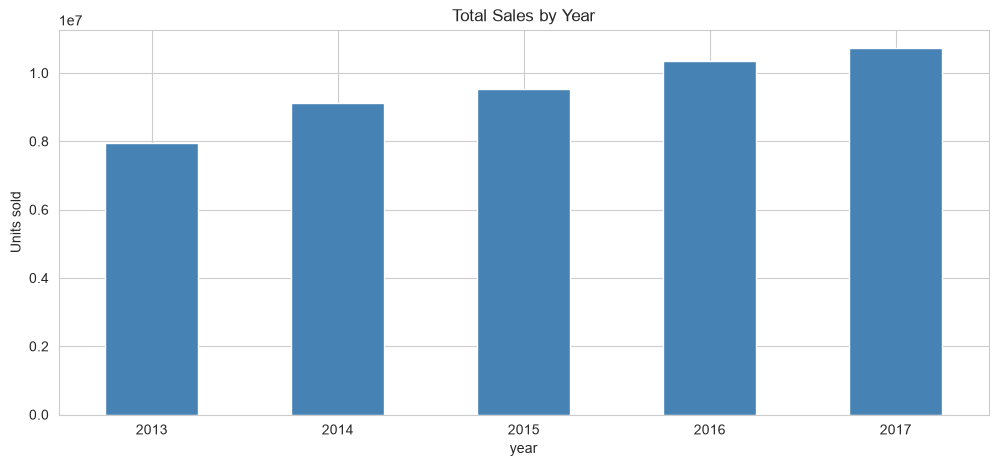

In [8]:
yearly = df.groupby('year')['sales'].sum()
growth = yearly.pct_change() * 100

print(pd.DataFrame({'total_sales': yearly, 'growth_%': growth.round(1)}))

yearly.plot(kind='bar', color='steelblue')
plt.title('Total Sales by Year')
plt.ylabel('Units sold')
plt.xticks(rotation=0)
plt.show()

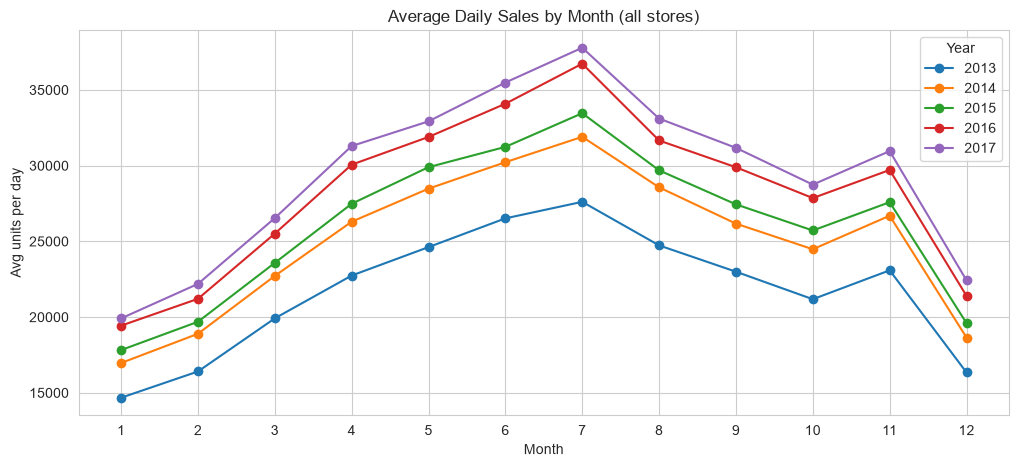

In [9]:
daily_total = df.groupby('date')['sales'].sum().reset_index()
daily_total['year']  = daily_total['date'].dt.year
daily_total['month'] = daily_total['date'].dt.month

monthly = daily_total.groupby(['year', 'month'])['sales'].mean().unstack(level=0)
monthly.plot(marker='o')
plt.title('Average Daily Sales by Month (all stores)')
plt.xlabel('Month')
plt.ylabel('Avg units per day')
plt.xticks(range(1, 13))
plt.legend(title='Year')
plt.show()

    day_name         sales  vs_avg_%
0     Monday  20714.819231     -20.7
1    Tuesday  24112.954023      -7.7
2  Wednesday  24184.252874      -7.4
3   Thursday  25861.609195      -1.0
4     Friday  27578.624521       5.6
5   Saturday  29331.348659      12.3
6     Sunday  31071.666667      18.9


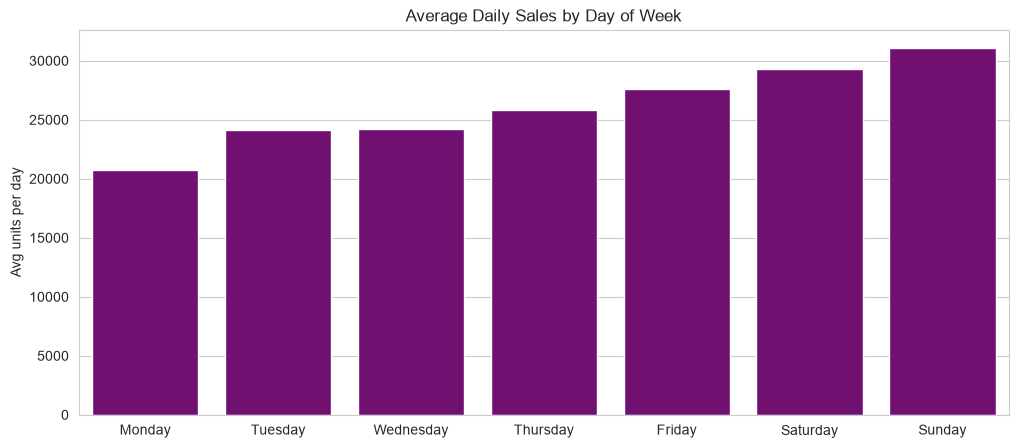

In [10]:
dow = daily_total.copy()
dow['day_name'] = dow['date'].dt.day_name()
dow['weekday']  = dow['date'].dt.dayofweek

dow_avg = dow.groupby(['weekday', 'day_name'])['sales'].mean().reset_index()
dow_avg['vs_avg_%'] = ((dow_avg['sales'] / dow_avg['sales'].mean() - 1) * 100).round(1)
print(dow_avg[['day_name', 'sales', 'vs_avg_%']])

sns.barplot(data=dow_avg, x='day_name', y='sales', color='purple')
plt.title('Average Daily Sales by Day of Week')
plt.xlabel('')
plt.ylabel('Avg units per day')
plt.show()

       total_sales  share_%
store                      
2          6120128     12.8
8          5856169     12.3
3          5435144     11.4
10         5360158     11.2
9          5025976     10.5
4          5012639     10.5
1          4315603      9.0
5          3631016      7.6
6          3627670      7.6
7          3320009      7.0


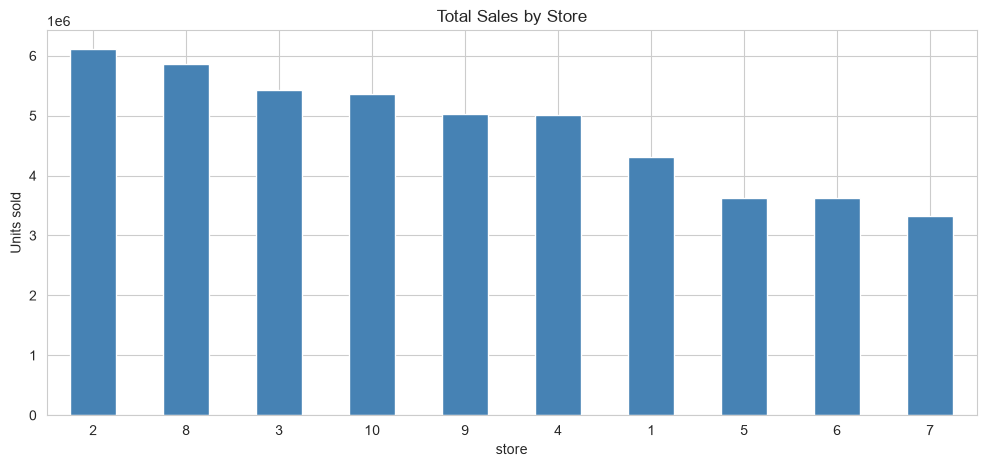

In [11]:
store_sales = df.groupby('store')['sales'].sum().sort_values(ascending=False)
store_share = (store_sales / store_sales.sum() * 100).round(1)
print(pd.DataFrame({'total_sales': store_sales, 'share_%': store_share}))

store_sales.plot(kind='bar', color='steelblue')
plt.title('Total Sales by Store')
plt.ylabel('Units sold')
plt.xticks(rotation=0)
plt.show()

Top 5 items:
 item
15    1607442
28    1604713
13    1539621
18    1538876
25    1473334
Name: sales, dtype: int64

Bottom 5 items:
 item
4     401907
47    401781
41    401759
1     401384
5     335230
Name: sales, dtype: int64


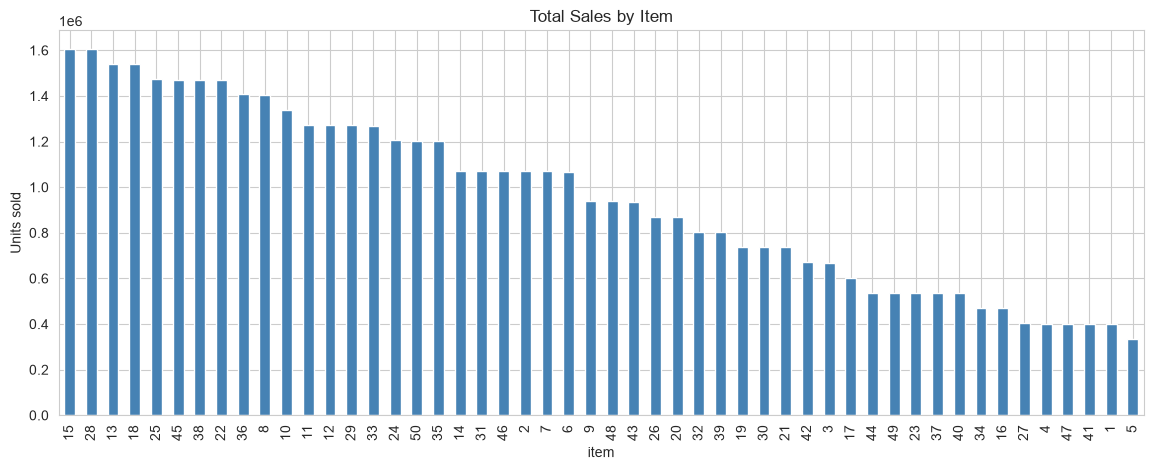

In [12]:
item_sales = df.groupby('item')['sales'].sum().sort_values(ascending=False)
print("Top 5 items:\n", item_sales.head())
print("\nBottom 5 items:\n", item_sales.tail())

item_sales.plot(kind='bar', color='steelblue', figsize=(14, 5))
plt.title('Total Sales by Item')
plt.ylabel('Units sold')
plt.show()

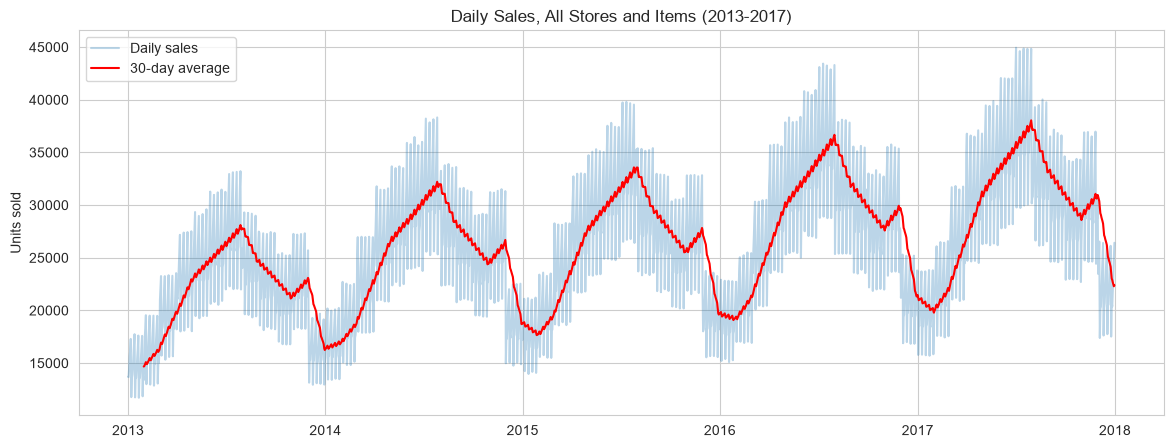

In [13]:
daily_total = daily_total.set_index('date')
daily_total['rolling_30'] = daily_total['sales'].rolling(30).mean()

plt.figure(figsize=(14, 5))
plt.plot(daily_total.index, daily_total['sales'], alpha=0.3, label='Daily sales')
plt.plot(daily_total.index, daily_total['rolling_30'], color='red', label='30-day average')
plt.title('Daily Sales, All Stores and Items (2013-2017)')
plt.ylabel('Units sold')
plt.legend()
plt.show()

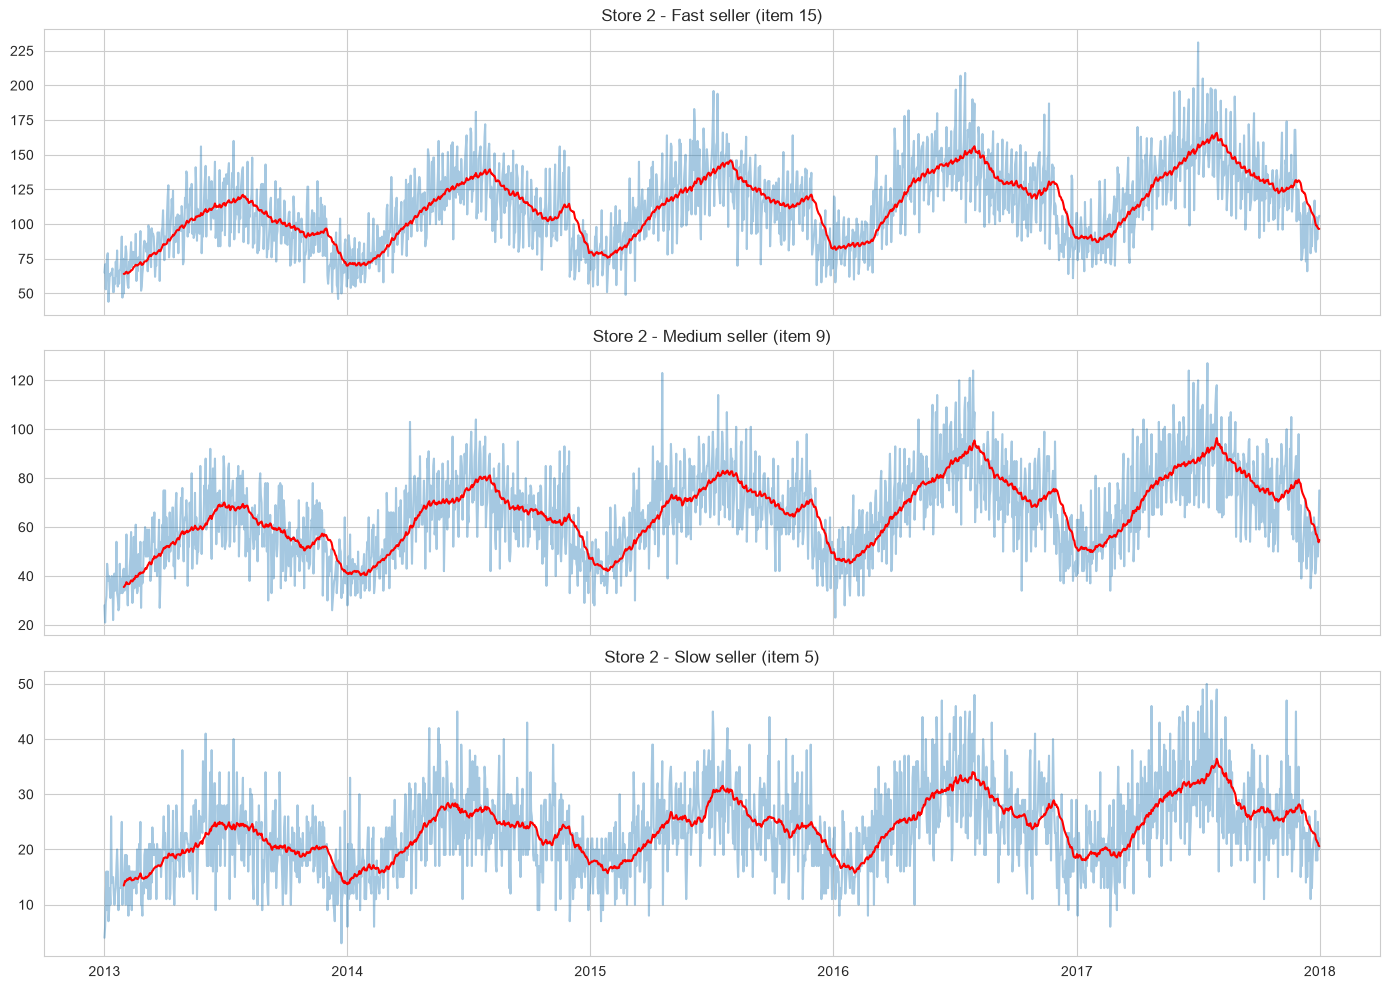

In [14]:
STORE = 2   # the busiest store: most sales, so the most at stake
ITEMS = {'Fast seller (item 15)': 15,
         'Medium seller (item 9)': 9,
         'Slow seller (item 5)': 5}

series = {}
for label, item in ITEMS.items():
    s = df[(df['store'] == STORE) & (df['item'] == item)].set_index('date')['sales']
    series[label] = s.asfreq('D')      # tell pandas it's a daily series

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, (label, s) in zip(axes, series.items()):
    ax.plot(s, alpha=0.4)
    ax.plot(s.rolling(30).mean(), color='red')
    ax.set_title(f'Store {STORE} - {label}')
plt.tight_layout()
plt.show()

In [15]:
TEST_START = '2017-10-01'

train = {k: s[s.index <  TEST_START] for k, s in series.items()}
test  = {k: s[s.index >= TEST_START] for k, s in series.items()}

k = list(series)[0]
print("Train:", train[k].index.min().date(), "to", train[k].index.max().date(), f"({len(train[k])} days)")
print("Test: ", test[k].index.min().date(),  "to", test[k].index.max().date(),  f"({len(test[k])} days)")

Train: 2013-01-01 to 2017-09-30 (1734 days)
Test:  2017-10-01 to 2017-12-31 (92 days)


In [16]:
def mape(actual, forecast):
    """Mean Absolute Percentage Error: average % the forecast is off by."""
    actual, forecast = np.array(actual), np.array(forecast)
    mask = actual != 0                       # avoid dividing by zero
    return np.mean(np.abs((actual[mask] - forecast[mask]) / actual[mask])) * 100

In [17]:
results = []
baseline_fc = {}

for k in series:
    level = train[k].tail(30).mean()          # average of the last 30 days
    fc = pd.Series(level, index=test[k].index)
    baseline_fc[k] = fc
    results.append({'series': k,
                    'avg_daily_sales_test': round(test[k].mean(), 1),
                    'baseline_MAPE_%': round(mape(test[k], fc), 1)})

results_df = pd.DataFrame(results)
results_df

,series,avg_daily_sales_test,baseline_MAPE_%
0,Fast seller (item 15),117.0,22.7
1,Medium seller (item 9),68.1,27.0
2,Slow seller (item 5),24.7,26.6


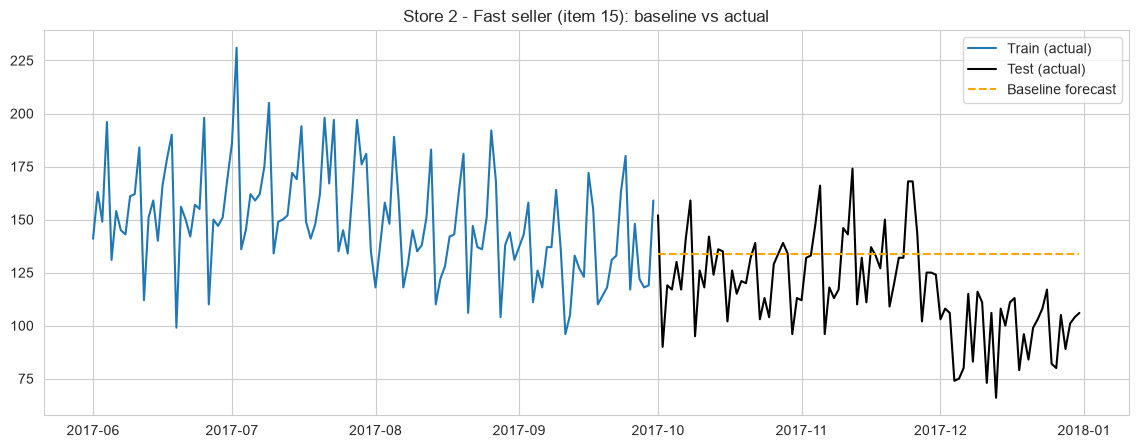

In [18]:
k = 'Fast seller (item 15)'
plt.figure(figsize=(14, 5))
plt.plot(train[k]['2017-06-01':], label='Train (actual)')
plt.plot(test[k], label='Test (actual)', color='black')
plt.plot(baseline_fc[k], label='Baseline forecast', color='orange', linestyle='--')
plt.title(f'Store {STORE} - {k}: baseline vs actual')
plt.legend()
plt.show()

In [19]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import warnings
warnings.filterwarnings('ignore')   # statsmodels prints harmless optimiser warnings

In [20]:
hw_weekly_fc = {}

for k in series:
    model = ExponentialSmoothing(train[k],
                                 trend='add', damped_trend=True,
                                 seasonal='mul', seasonal_periods=7).fit()
    hw_weekly_fc[k] = model.forecast(len(test[k]))

results_df['HW_weekly_MAPE_%'] = [round(mape(test[k], hw_weekly_fc[k]), 1) for k in series]
results_df

,series,avg_daily_sales_test,baseline_MAPE_%,HW_weekly_MAPE_%
0,Fast seller (item 15),117.0,22.7,18.9
1,Medium seller (item 9),68.1,27.0,22.9
2,Slow seller (item 5),24.7,26.6,24.0


In [21]:
def monthly_index(s):
    """How much each month sells vs. its year's average (1.20 = 20% above)."""
    full_years = s['2013':'2016']                         # complete years only
    m = full_years.groupby([full_years.index.year, full_years.index.month]).mean()
    ratio = m / m.groupby(level=0).transform('mean')      # month vs its own year
    return ratio.groupby(level=1).mean()                  # average across years

idx = {k: monthly_index(train[k]) for k in series}
pd.DataFrame(idx).round(2)

,Fast seller (item 15),Medium seller (item 9),Slow seller (item 5)
date,,,
1,0.68,0.66,0.69
2,0.76,0.76,0.75
3,0.92,0.92,0.92
4,1.05,1.07,1.04
5,1.15,1.12,1.15
6,1.21,1.23,1.22
7,1.28,1.28,1.28
8,1.13,1.13,1.11
9,1.05,1.06,1.05


In [22]:
hw_full_fc = {}

for k in series:
    month_factor_train = train[k].index.month.map(idx[k]).values
    adjusted = train[k] / month_factor_train               # 1. remove yearly pattern

    model = ExponentialSmoothing(adjusted,
                                 trend='add', damped_trend=True,
                                 seasonal='mul', seasonal_periods=7).fit()
    fc_adjusted = model.forecast(len(test[k]))              # 2. forecast weekly + trend

    month_factor_test = test[k].index.month.map(idx[k]).values
    hw_full_fc[k] = fc_adjusted * month_factor_test         # 3. put yearly pattern back

results_df['HW_weekly+yearly_MAPE_%'] = [round(mape(test[k], hw_full_fc[k]), 1) for k in series]
results_df

,series,avg_daily_sales_test,baseline_MAPE_%,HW_weekly_MAPE_%,HW_weekly+yearly_MAPE_%
0,Fast seller (item 15),117.0,22.7,18.9,6.5
1,Medium seller (item 9),68.1,27.0,22.9,10.1
2,Slow seller (item 5),24.7,26.6,24.0,14.7


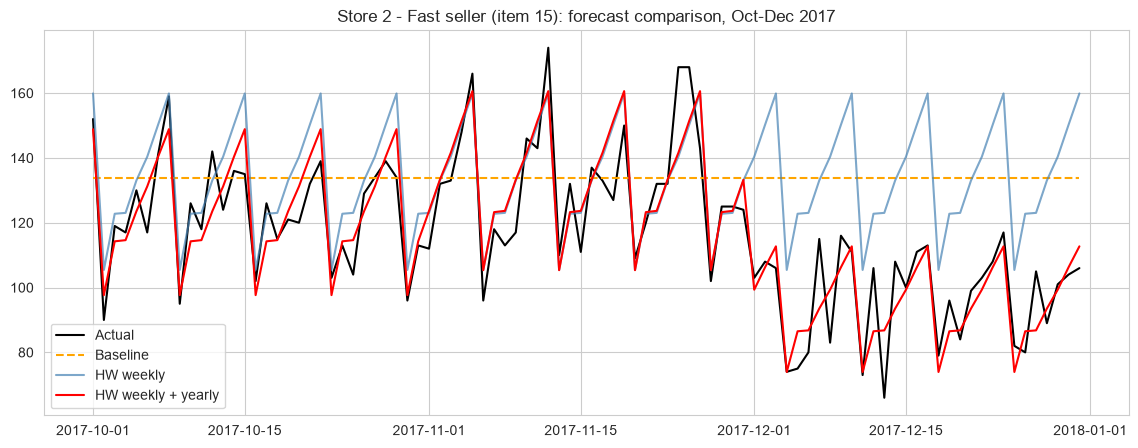

In [23]:
k = 'Fast seller (item 15)'
plt.figure(figsize=(14, 5))
plt.plot(test[k], label='Actual', color='black')
plt.plot(baseline_fc[k], label='Baseline', color='orange', linestyle='--')
plt.plot(hw_weekly_fc[k], label='HW weekly', color='steelblue', alpha=0.7)
plt.plot(hw_full_fc[k], label='HW weekly + yearly', color='red')
plt.title(f'Store {STORE} - {k}: forecast comparison, Oct-Dec 2017')
plt.legend()
plt.show()

In [24]:
LEAD_TIME = 7       # days
Z = 1.65            # 95% service level

In [25]:
inv = []
for k in series:
    err_base  = test[k] - baseline_fc[k]
    err_model = test[k] - hw_full_fc[k]
    ss_base  = Z * err_base.std()  * np.sqrt(LEAD_TIME)
    ss_model = Z * err_model.std() * np.sqrt(LEAD_TIME)
    inv.append({'series': k,
                'error_std_baseline': round(err_base.std(), 1),
                'error_std_model':    round(err_model.std(), 1),
                'safety_stock_baseline': round(ss_base),
                'safety_stock_model':    round(ss_model),
                'safety_stock_saved_%':  round((1 - ss_model / ss_base) * 100, 1)})

inv_df = pd.DataFrame(inv)
inv_df

,series,error_std_baseline,error_std_model,safety_stock_baseline,safety_stock_model,safety_stock_saved_%
0,Fast seller (item 15),22.7,9.6,99,42,57.6
1,Medium seller (item 9),16.2,8.1,71,36,49.7
2,Slow seller (item 5),6.6,4.7,29,21,28.3


In [26]:
def monthly_index(s, last_full_year='2016'):
    full_years = s['2013':last_full_year]
    m = full_years.groupby([full_years.index.year, full_years.index.month]).mean()
    ratio = m / m.groupby(level=0).transform('mean')
    return ratio.groupby(level=1).mean()

HORIZON = 90   # Jan 1 - Mar 31, 2018
future_fc = {}

for k, s in series.items():
    m_idx = monthly_index(s, last_full_year='2017')       # now 5 full years
    adjusted = s / s.index.month.map(m_idx).values
    model = ExponentialSmoothing(adjusted, trend='add', damped_trend=True,
                                 seasonal='mul', seasonal_periods=7).fit()
    fc = model.forecast(HORIZON)
    future_fc[k] = fc * fc.index.month.map(m_idx).values

print(future_fc['Fast seller (item 15)'].head(10).round(1))

2018-01-01     68.9
2018-01-02     80.7
2018-01-03     80.6
2018-01-04     87.2
2018-01-05     92.4
2018-01-06     98.9
2018-01-07    104.8
2018-01-08     68.9
2018-01-09     80.7
2018-01-10     80.6
Freq: D, dtype: float64


In [27]:
plan = []
for k in series:
    ss = Z * (test[k] - hw_full_fc[k]).std() * np.sqrt(LEAD_TIME)
    monthly_avg = future_fc[k].groupby(future_fc[k].index.month).mean()
    for month, avg_daily in monthly_avg.items():
        plan.append({'series': k,
                     'month': pd.Timestamp(2018, month, 1).strftime('%b %Y'),
                     'forecast_avg_daily': round(avg_daily, 1),
                     'demand_during_lead_time': round(avg_daily * LEAD_TIME),
                     'safety_stock': round(ss),
                     'reorder_point': round(avg_daily * LEAD_TIME + ss)})

plan_df = pd.DataFrame(plan)
plan_df

,series,month,forecast_avg_daily,demand_during_lead_time,safety_stock,reorder_point
0,Fast seller (item 15),Jan 2018,86.6,606,42,648
1,Fast seller (item 15),Feb 2018,96.8,678,42,720
2,Fast seller (item 15),Mar 2018,117.2,820,42,862
3,Medium seller (item 9),Jan 2018,48.0,336,36,372
4,Medium seller (item 9),Feb 2018,55.3,387,36,423
5,Medium seller (item 9),Mar 2018,67.1,469,36,505
6,Slow seller (item 5),Jan 2018,18.4,129,21,150
7,Slow seller (item 5),Feb 2018,19.9,139,21,160
8,Slow seller (item 5),Mar 2018,24.5,171,21,192


In [28]:
results_df.to_csv('forecast_accuracy.csv', index=False)
inv_df.to_csv('safety_stock_comparison.csv', index=False)
plan_df.to_csv('reorder_plan_2018.csv', index=False)

fc_out = pd.concat([f.rename('forecast').to_frame().assign(series=k)
                    for k, f in future_fc.items()]).reset_index(names='date')
fc_out.to_csv('daily_forecast_2018.csv', index=False)
print("Saved 4 files")

Saved 4 files
